# 04. Sori Density Engineering

This notebook engineers a new variable, sori density (sori per unit of leaf area), to ask a different question than the one already answered in `02_total_sori_imputation`: not how many sori an individual has in total, but whether larger fronds pack sori more densely, at the same density, or more sparsely. We test this both with direct correlations and with an allometric scaling model, and export the dataset with this new feature for the rest of the pipeline.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import OLSInfluence
from statsmodels.stats.multitest import multipletests
from scipy.stats import pearsonr, spearmanr
from sklearn.linear_model import TheilSenRegressor

## 2. Load Data

We load the imputed Fronds dataset from `02_total_sori_imputation`, which already includes `n_pinna_rows` and H15's imputed `n_sori_total`.

In [2]:
df_fronds_imputed = pd.read_csv("../data/processed/fronds_imputed.csv")

Quick check of the loaded data:

In [3]:
df_fronds_imputed.head()

,individual_id,frond_length_cm,frond_width_cm,n_sori_total,leaf_area_cm2,n_pinna_rows,is_imputed
0,H01,63.0,8.4,1656,280.0,86,False
1,H02,42.0,5.8,1554,130.0,59,False
2,H03,68.5,8.1,1728,266.0,80,False
3,H04,66.0,7.1,1826,216.0,89,False
4,H05,60.7,6.0,1456,194.0,82,False


## 3. Engineering Sori Density

So far, `n_sori_total` measures the total sori count per individual, but this figure is naturally confounded with frond size: a larger frond has more physical space and is therefore expected to carry more sori simply by being bigger, without that necessarily reflecting a different reproductive strategy. To separate size from a genuine density effect, we normalize sori count by leaf area, defining `sori_density = n_sori_total / leaf_area_cm2`.

This normalization lets us ask a different question than the one already answered with `n_sori_total`: do larger fronds concentrate more sori per unit of area (higher density), the same relative amount (constant density), or fewer (decreasing density)? That relationship is what we explore in this notebook.

In [4]:
df_fronds_density = df_fronds_imputed.copy()
df_fronds_density["sori_density"] = (df_fronds_density["n_sori_total"] / df_fronds_density["leaf_area_cm2"]).round(2)

df_fronds_density

,individual_id,frond_length_cm,frond_width_cm,n_sori_total,leaf_area_cm2,n_pinna_rows,is_imputed,sori_density
0,H01,63.00,8.4,1656,280.0,86,False,5.91
1,H02,42.00,5.8,1554,130.0,59,False,11.95
2,H03,68.50,8.1,1728,266.0,80,False,6.50
3,H04,66.00,7.1,1826,216.0,89,False,8.45
4,H05,60.70,6.0,1456,194.0,82,False,7.51
5,H06,62.40,6.9,1290,229.0,85,False,5.63
6,H07,67.20,7.8,1590,287.0,91,False,5.54
7,H08,55.00,6.1,644,194.0,81,False,3.32
8,H09,66.00,6.8,1296,196.0,74,False,6.61
9,H10,51.30,6.4,1464,117.0,62,False,12.51


## 4. Does Frond Size Predict Sori Density?

### 4.1 Scatter Plots

We plot `sori_density` against the three available size variables (`frond_length_cm`, `frond_width_cm`, `leaf_area_cm2`) to look for a visual trend. One methodological note before interpreting these plots: since `sori_density` was computed by dividing `n_sori_total` by `leaf_area_cm2`, any correlation between `sori_density` and `leaf_area_cm2` specifically is partly a mathematical artifact of that division, not necessarily an independent biological relationship, a point we return to after the correlation analysis.

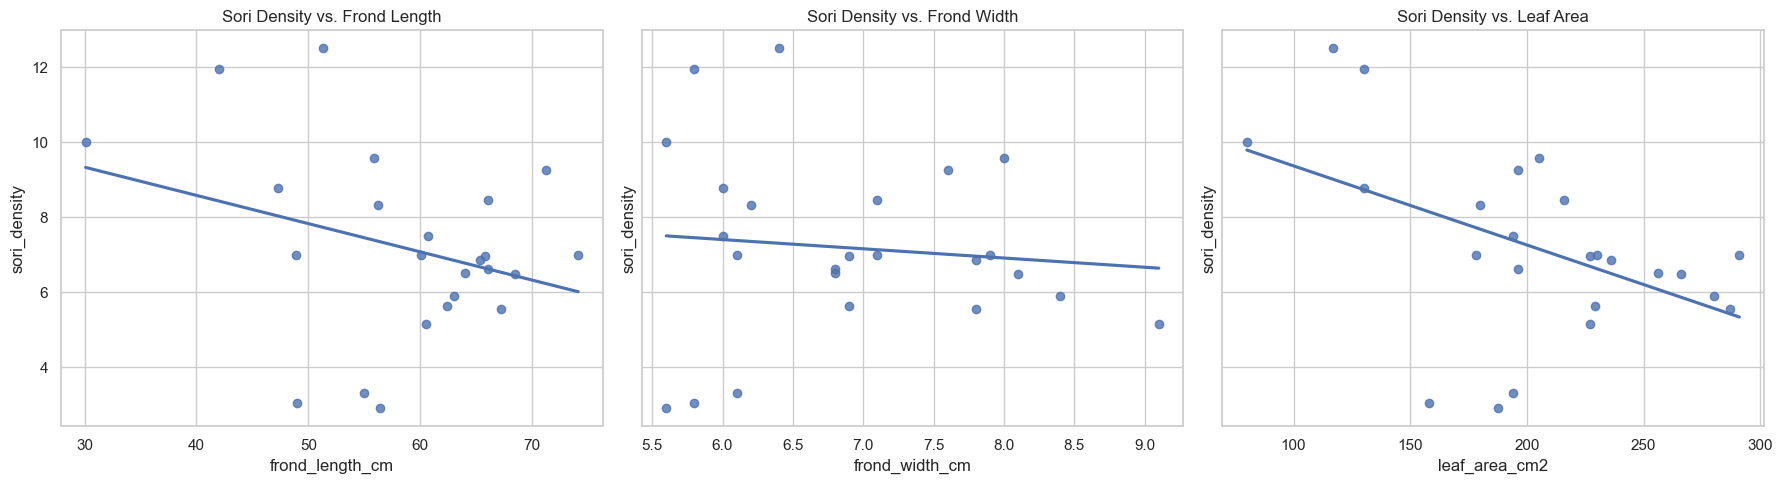

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

sns.regplot(x="frond_length_cm", y="sori_density", data=df_fronds_density, ax=axes[0], ci=None)
axes[0].set_title("Sori Density vs. Frond Length")

sns.regplot(x="frond_width_cm", y="sori_density", data=df_fronds_density, ax=axes[1], ci=None)
axes[1].set_title("Sori Density vs. Frond Width")

sns.regplot(x="leaf_area_cm2", y="sori_density", data=df_fronds_density, ax=axes[2], ci=None)
axes[2].set_title("Sori Density vs. Leaf Area")

plt.tight_layout()
plt.show()


### 4.2 Correlation Analysis

We compute both Pearson and Spearman correlations between `sori_density` and each size variable, since we have no prior reason to assume the relationship is linear rather than simply monotonic.

In [6]:
size_vars = ["frond_length_cm", "frond_width_cm", "leaf_area_cm2"]

density_results = []

for var in size_vars:
    r, p_r = pearsonr(df_fronds_density[var], df_fronds_density["sori_density"])
    rho, p_rho = spearmanr(df_fronds_density[var], df_fronds_density["sori_density"])

    density_results.append({
        "variable": var,
        "pearson_r": r,
        "pearson_p": p_r,
        "spearman_rho": rho,
        "spearman_p": p_rho,
    })

df_density_correlations = pd.DataFrame(density_results)
df_density_correlations.round(3)

,variable,pearson_r,pearson_p,spearman_rho,spearman_p
0,frond_length_cm,-0.311,0.139,-0.253,0.233
1,frond_width_cm,-0.099,0.644,-0.147,0.492
2,leaf_area_cm2,-0.470,0.020,-0.436,0.033


`leaf_area_cm2` is the only variable showing a correlation of meaningful size with `sori_density` (Pearson r = -0.470, p = 0.020; Spearman rho = -0.436, p = 0.033), both `frond_length_cm` and `frond_width_cm` show weak, non-significant correlations (Pearson p = 0.139 and 0.644; Spearman p = 0.233 and 0.492).

Since `sori_density` was computed by dividing `n_sori_total` by `leaf_area_cm2`, a negative correlation between the two is partly mathematically expected rather than purely biological. However, the fact that this correlation is negative (and not null) is still informative: if sori count scaled exactly proportionally to area, density would be constant regardless of area, and the correlation would be near zero. A negative correlation instead suggests count grows more slowly than area, consistent with what the log-log regression in Section 5 tests directly.

By contrast, the absence of correlation with `frond_length_cm` and `frond_width_cm` (which do not enter the density calculation, making these clean comparisons) suggests that no single linear dimension of the frond, on its own, predicts how dense in sori it will be, frond size alone does not determine reproductive density.

### 4.3 Multiple Testing Correction (Bonferroni)

Since we run 3 simultaneous correlation tests (one per size variable), we apply the Bonferroni correction to control the risk of false positives, adjusting the significance threshold from 0.05 to approximately 0.017 (0.05/3).

In [7]:
reject_pearson, p_bonf_pearson, _, _ = multipletests(
    df_density_correlations["pearson_p"], alpha=0.05, method="bonferroni"
)
reject_spearman, p_bonf_spearman, _, _ = multipletests(
    df_density_correlations["spearman_p"], alpha=0.05, method="bonferroni"
)

df_density_correlations["pearson_p_bonferroni"] = p_bonf_pearson
df_density_correlations["pearson_sig_bonferroni"] = reject_pearson
df_density_correlations["spearman_p_bonferroni"] = p_bonf_spearman
df_density_correlations["spearman_sig_bonferroni"] = reject_spearman

df_density_correlations.round(3)

,variable,pearson_r,pearson_p,spearman_rho,spearman_p,pearson_p_bonferroni,pearson_sig_bonferroni,spearman_p_bonferroni,spearman_sig_bonferroni
0,frond_length_cm,-0.311,0.139,-0.253,0.233,0.418,False,0.698,False
1,frond_width_cm,-0.099,0.644,-0.147,0.492,1.000,False,1.000,False
2,leaf_area_cm2,-0.470,0.020,-0.436,0.033,0.061,False,0.100,False


After the Bonferroni correction, none of the three correlations remain significant, not even `leaf_area_cm2`, whose adjusted p-values (0.061 for Pearson, 0.100 for Spearman) now exceed even the original 0.05 threshold, let alone the corrected 0.017. This indicates that, while there is a visually plausible downward trend between `sori_density` and `leaf_area_cm2`, it is not statistically robust once multiple testing is accounted for.

## 5. Allometric Scaling: Log-Log Regression

The analysis above ruled out a robust relationship between `sori_density` (n_sori_total / area) and frond dimensions, but that result is limited by a methodological weakness: `sori_density` mathematically combines both variables into a single ratio, which makes it harder to interpret *how* sori count scales with area specifically, a ratio can stay constant, decrease, or increase with size in ways not fully captured by a single correlation coefficient.

This question corresponds to allometric scaling, widely used in biology to study how a trait changes in relation to organism size. We model the relationship as `n_sori_total = a · area^b`, where the exponent `b` determines the type of growth: `b=1` means sori count grows exactly proportionally to area (isometry); `b<1` means it grows more slowly than area (negative allometry, consistent with the negative density correlation found above); `b>1` would mean it grows faster (positive allometry). Taking the logarithm of both sides linearizes this relationship,  `log(n_sori_total) = log(a) + b·log(area)`, which can be estimated with ordinary linear regression on the log-transformed variables.

### 5.1 Fitting the Log-Log Model

In [8]:
log_area = np.log(df_fronds_density["leaf_area_cm2"])
log_sori = np.log(df_fronds_density["n_sori_total"])

X_log = sm.add_constant(log_area)
model_log_log = sm.OLS(log_sori, X_log).fit()

print(model_log_log.summary())

ci = model_log_log.conf_int(alpha=0.05).loc["leaf_area_cm2"]
print(f"\n95% CI for b: [{ci[0]:.3f}, {ci[1]:.3f}]")

                            OLS Regression Results                            
Dep. Variable:           n_sori_total   R-squared:                       0.195
Model:                            OLS   Adj. R-squared:                  0.159
Method:                 Least Squares   F-statistic:                     5.339
Date:                Tue, 28 Jul 2026   Prob (F-statistic):             0.0306
Time:                        21:39:37   Log-Likelihood:                -8.4805
No. Observations:                  24   AIC:                             20.96
Df Residuals:                      22   BIC:                             23.32
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             4.2301      1.281      3.302

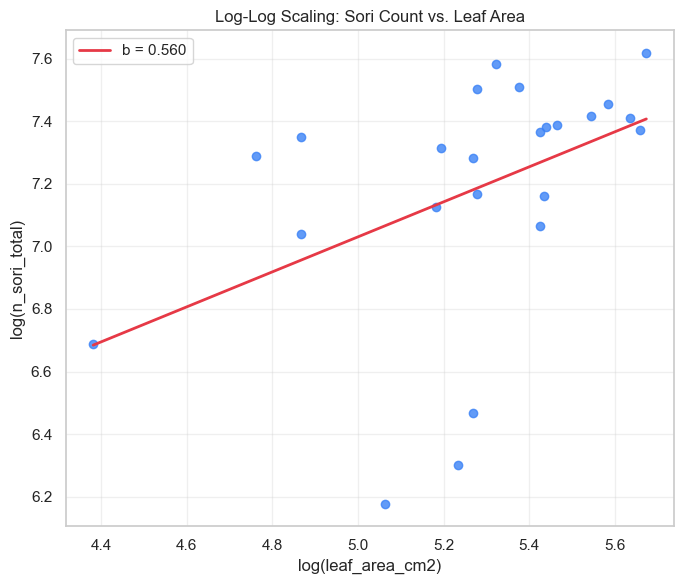

In [10]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(log_area, log_sori, color="#3b82f6", alpha=0.8)

x_line = np.linspace(log_area.min(), log_area.max(), 100)
y_line = model_log_log.params["const"] + model_log_log.params["leaf_area_cm2"] * x_line
ax.plot(x_line, y_line, color="#e63946", lw=2, label=f"b = {model_log_log.params['leaf_area_cm2']:.3f}")

ax.set_xlabel("log(leaf_area_cm2)")
ax.set_ylabel("log(n_sori_total)")
ax.set_title("Log-Log Scaling: Sori Count vs. Leaf Area")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../outputs/figures/04_allometric_scaling.png", dpi=300, bbox_inches="tight")
plt.show()

The log-log regression estimates a scaling exponent of b=0.560, directionally consistent with negative allometry: sori count increases with leaf area, but at a slower relative rate, meaning larger fronds are systematically less efficient reproducers per unit of leaf tissue than smaller ones. This lines up with the negative density-area correlation from Section 4, and points toward a possible trade-off in reproductive strategy: investing in more, moderately sized fronds could be reproductively more efficient per unit of leaf area than investing in fewer, larger ones. The 95% CI ([0.057, 1.063]) is wide enough to include b=1, so isometric (proportional) growth cannot be formally ruled out at this sample size, a direction worth testing with a larger sample, not a reason to discount the pattern observed here.

### 5.2 Regression Diagnostics (Cook's Distance)

Since the log-log model's residuals show evidence of non-normality and marked negative skew (Jarque-Bera p = 0.004, skew = -1.486), it is worth checking whether this departure is driven by the disproportionate influence of one or a few observations, rather than reflecting a genuine property of the underlying relationship, the same diagnostic approach used for the OLS model in `02_total_sori_imputation`.

In [19]:
influence_log = OLSInfluence(model_log_log)
cooks_d_log = influence_log.cooks_distance[0]

df_fronds_cooks_log = df_fronds_density.copy()
df_fronds_cooks_log["cooks_d"] = cooks_d_log.round(3)
df_fronds_cooks_log["leverage"] = influence_log.hat_matrix_diag.round(3)
df_fronds_cooks_log["studentized_resid"] = influence_log.resid_studentized_internal.round(3)

threshold_cooks = 4 / len(df_fronds_density)
print(f"Reference threshold (4/n): {threshold_cooks:.3f}\n")

df_fronds_cooks_log[["individual_id", "leaf_area_cm2", "n_sori_total", "cooks_d", "leverage", "studentized_resid"]] \
    .sort_values("cooks_d", ascending=False)

Reference threshold (4/n): 0.167



,individual_id,leaf_area_cm2,n_sori_total,cooks_d,leverage,studentized_resid
19,H20,158.0,482,0.216,0.062,-2.547
9,H10,117.0,1464,0.136,0.161,1.188
18,H19,187.6,546,0.132,0.042,-2.440
1,H02,130.0,1554,0.089,0.117,1.160
7,H08,194.0,644,0.089,0.042,-2.024
11,H12,205.0,1966,0.025,0.043,1.057
17,H18,291.0,2036,0.025,0.113,0.623
23,H24,196.0,1814,0.018,0.042,0.900
3,H04,216.0,1826,0.014,0.046,0.766
12,H13,227.0,1170,0.009,0.052,-0.582


The influence analysis on the log-log model shows that H20 is the only individual exceeding the Cook's reference threshold (0.216 > 0.167). Unlike H13 in the previous regression (`02_total_sori_imputation`), this influence is not driven by an extreme leaf-area value (leverage = 0.062, low), it stems instead from an atypical residual: H20's sori count deviates more from what the model predicts than expected for its area, rather than H20 having an unusually extreme area itself.

### 5.3 Robustness Check: Theil-Sen

Since H20 concentrates the most influence on the log-log OLS model, mainly through an atypical residual rather than an extreme predictor value, it is worth checking whether the estimated scaling exponent (b=0.560) is sensitive to this point, or whether it holds stable under a robust method. We refit the relationship with Theil-Sen, which is less sensitive to outliers than OLS.

In [20]:
theil_sen_log = TheilSenRegressor(random_state=42)
theil_sen_log.fit(log_area.values.reshape(-1, 1), log_sori.values)

b_ols = model_log_log.params["leaf_area_cm2"]
b_theil = theil_sen_log.coef_[0]

print(f"Exponent b (OLS):       {b_ols:.3f}")
print(f"Exponent b (Theil-Sen): {b_theil:.3f}")
print(f"Difference: {abs(b_ols - b_theil):.3f} ({abs(b_ols - b_theil)/b_ols*100:.1f}%)")

Exponent b (OLS):       0.560
Exponent b (Theil-Sen): 0.548
Difference: 0.012 (2.2%)


The scaling exponent estimated via Theil-Sen (b=0.548) is nearly identical to the OLS estimate (b=0.560), a difference of only 2.2%. Unlike the multiple regression for `n_sori_total` in `02_total_sori_imputation` (where H13 caused coefficient shifts of 30-50%), H20's influence here is comparatively minor, the negative-allometry pattern is not an artifact of a single point, it holds regardless of estimation method. This strengthens confidence in b ≈ 0.55 as a genuine, stable estimate of reduced reproductive efficiency in larger fronds, with the caveat that a larger sample would be needed to formally confirm it departs from proportional (isometric) growth.

## 6. Export Dataset with Engineered Features

We export `df_fronds_density`, which adds `sori_density` to the imputed Fronds dataset, for use in the rest of the pipeline.

In [21]:
df_fronds_density.to_csv("../data/processed/fronds_density.csv", index=False)

print(f"df_fronds_density exported: {df_fronds_density.shape[0]} rows × {df_fronds_density.shape[1]} columns")

df_fronds_density exported: 24 rows × 8 columns


Taken together, the evidence points in a consistent direction: larger fronds do not scale their sori count proportionally to their leaf area. Both the density correlations in Section 4 and the allometric exponent (b ≈ 0.55, stable across OLS and Theil-Sen) suggest that reproductive investment per unit of leaf tissue declines as fronds grow, pointing toward smaller-to-medium fronds being reproductively more efficient per unit of leaf area. This pattern is directional rather than formally confirmed: the individual density correlations do not survive correction for multiple comparisons, and the allometric exponent's confidence interval cannot yet rule out proportional (isometric) growth, a larger sample would be needed to confirm it statistically. `sori_density` is not used as an input in any later notebook; it is exported here only as a record of this analysis, in case it is useful for future exploration and hypothesis testing on a larger dataset. The next notebook (`05_frond_shape_factor`) works directly from `fronds_imputed.csv`, not from this file, and estimates the species' characteristic shape factor K, enabling area estimation from linear measurements alone.